<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Setup and Imports
We begin by importing NumPy for computations, SciPy for statistical helper functions, and Matplotlib for visualizing binary cross-entropy loss.

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

print("Libraries successfully imported!")

Libraries successfully imported!


## Tasks 1 & 2: Generate Simulated Data and Compute Information Metrics
We will define the observed (true) distribution of weather over 30 days and compare two competing forecasting models (Model A and Model B) against this ground truth.

In [2]:
# 1. Define distributions (Sunny, Cloudy, Rainy)
# Observed true weather probabilities over 30 days (empirical distribution)
true_dist = np.array([0.5, 0.3, 0.2])

# Model A predictions (closer to true distribution)
model_a = np.array([0.45, 0.35, 0.20])

# Model B predictions (further from true distribution)
model_b = np.array([0.20, 0.50, 0.30])

# Helper function to compute entropy
def compute_entropy(p):
    return -np.sum(p * np.log2(p + 1e-12)) # Add small epsilon to prevent log(0)

# Helper function to compute cross-entropy
def compute_cross_entropy(p, q):
    return -np.sum(p * np.log2(q + 1e-12))

# Helper function to compute KL Divergence D_KL(P || Q)
def compute_kl_divergence(p, q):
    return np.sum(p * np.log2((p + 1e-12) / (q + 1e-12)))

# Calculations for observed, Model A, and Model B
H_true = compute_entropy(true_dist)

H_true_model_a = compute_cross_entropy(true_dist, model_a)
KL_true_model_a = compute_kl_divergence(true_dist, model_a)

H_true_model_b = compute_cross_entropy(true_dist, model_b)
KL_true_model_b = compute_kl_divergence(true_dist, model_b)

print(f"1. Entropy of observed distribution H(P): {H_true:.4f} bits\n")
print(f"2. Model A vs. True:")
print(f"   - Cross-Entropy H(P, Q_A): {H_true_model_a:.4f} bits")
print(f"   - KL Divergence D_KL(P || Q_A): {KL_true_model_a:.4f} bits\n")
print(f"   Model B vs. True:")
print(f"   - Cross-Entropy H(P, Q_B): {H_true_model_b:.4f} bits")
print(f"   - KL Divergence D_KL(P || Q_B): {KL_true_model_b:.4f} bits")

1. Entropy of observed distribution H(P): 1.4855 bits

2. Model A vs. True:
   - Cross-Entropy H(P, Q_A): 1.4948 bits
   - KL Divergence D_KL(P || Q_A): 0.0093 bits

   Model B vs. True:
   - Cross-Entropy H(P, Q_B): 1.8084 bits
   - KL Divergence D_KL(P || Q_B): 0.3229 bits


## Task 3: Verify that Cross-Entropy = Entropy + KL Divergence
Mathematically, $H(P, Q) = H(P) + D_{KL}(P \parallel Q)$. Let's verify this relation for both models.

In [3]:
print("Model A Verification:")
sum_a = H_true + KL_true_model_a
print(f"   H(P) + D_KL(P || Q_A) = {sum_a:.6f}")
print(f"   H(P, Q_A)             = {H_true_model_a:.6f}")
print(f"   Difference            = {abs(sum_a - H_true_model_a):.6e}\n")

print("Model B Verification:")
sum_b = H_true + KL_true_model_b
print(f"   H(P) + D_KL(P || Q_B) = {sum_b:.6f}")
print(f"   H(P, Q_B)             = {H_true_model_b:.6f}")
print(f"   Difference            = {abs(sum_b - H_true_model_b):.6e}")

Model A Verification:
   H(P) + D_KL(P || Q_A) = 1.494759
   H(P, Q_A)             = 1.494759
   Difference            = 2.220446e-16

Model B Verification:
   H(P) + D_KL(P || Q_B) = 1.808357
   H(P, Q_B)             = 1.808357
   Difference            = 2.220446e-16


## Task 4: Show that KL Divergence is Asymmetric
We will show that $D_{KL}(P \parallel Q) \neq D_{KL}(Q \parallel P)$.

In [4]:
KL_P_Q_A = compute_kl_divergence(true_dist, model_a)
KL_Q_A_P = compute_kl_divergence(model_a, true_dist)

print(f"D_KL(True || Model A) = {KL_P_Q_A:.6f} bits")
print(f"D_KL(Model A || True) = {KL_Q_A_P:.6f} bits")
print(f"Asymmetric Difference  = {abs(KL_P_Q_A - KL_Q_A_P):.6f} bits")

D_KL(True || Model A) = 0.009284 bits
D_KL(Model A || True) = 0.009436 bits
Asymmetric Difference  = 0.000152 bits


## Task 5: Plot Binary Cross-Entropy Loss against Predicted Probability
We will visualize how binary cross-entropy loss changes for a single sample when the true label is either 1 (positive class) or 0 (negative class).

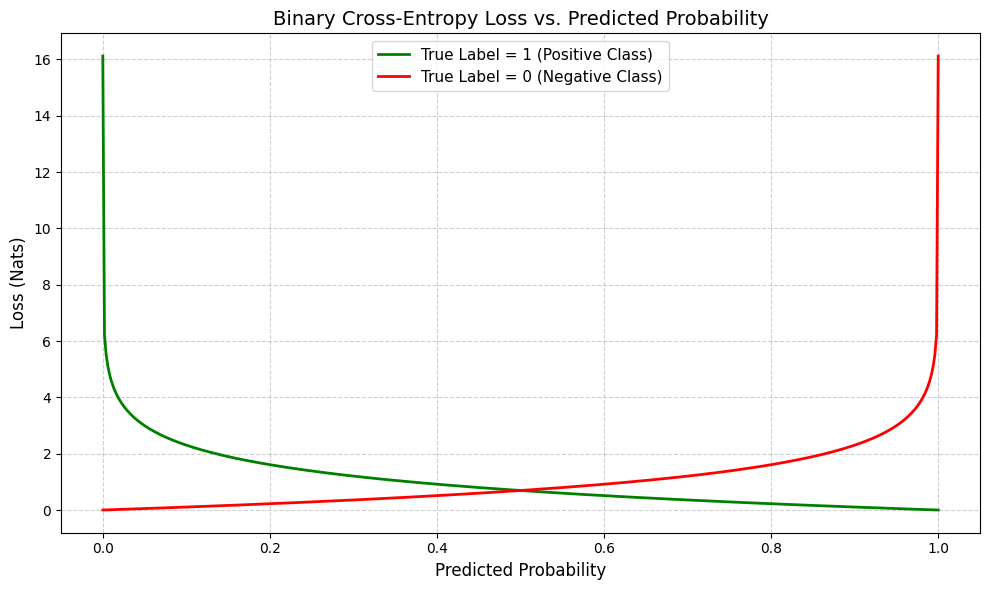

In [5]:
epsilon = 1e-7
probs = np.linspace(epsilon, 1 - epsilon, 500)

# Compute loss for True Label = 1 and True Label = 0
loss_y_1 = -np.log(probs)
loss_y_0 = -np.log(1 - probs)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(probs, loss_y_1, label='True Label = 1 (Positive Class)', color='green', linewidth=2)
ax.plot(probs, loss_y_0, label='True Label = 0 (Negative Class)', color='red', linewidth=2)

ax.set_title('Binary Cross-Entropy Loss vs. Predicted Probability', fontsize=14)
ax.set_xlabel('Predicted Probability', fontsize=12)
ax.set_ylabel('Loss (Nats)', fontsize=12)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(fontsize=11)

plt.tight_layout()
plt.show()